#                                                Capstone Project    
## Neural Networks applied to the placement of digital cells

# Section 1   -  Problem statement and Therotical background

In the section, we present the problem statement and objectives of this capstone project. Then, a short introduction to  therotical background  and literature review is provided. More details are given in the file data/capstone_project.pdf 

In the following sections, we use the terms gates, instances and cell inetrchangeable 

# Section 2  -  Data Preparation

## 2.1. From RTL to Gate Level  
  - Open source synthesis YOSYS
  - Chosen digital design with verilog behavioral model
  - YOSYS script to syntesis 
  - Gate Level verilog model 

### 2.1.1. YOSYS
 YOSYS is an open source framework  synthesis tool used widely in academia. The tool kernal is used in  major commercial tools. 
 The ongoing  development, maintenance, and commercial support of the project are managed by YosysHQ GmbH,  https://www.yosyshq.com/
 

## 2.1.2. Chosen design

The chosen digital design is refered as the "fiedler cooley", which is 10 bits counter(up3down5) in verilog designed by Larry Fiedler(web source).
        
This design is a classic benchmark hardware design, widely used in the electronic design automation (EDA) industry to 
test verilog synthesis tools, formal verification packages, and logic optimization engines like YosysHQ's Yosys(web source).
  - The verilog file is provided:         data/fiedler-cooley.v


## 2.1.3. YOSYS script
Steps required to sythesis the "fiedler cooley"  fiedler-cooley.v; converting the RTL(Register Transfer Level) verilog file into gate level netlist are grouped in this tcl(Tool Command Language; pronounced "tickle")  script file accessible in:    data/run_yosys.tcl

### 2.1.4. Gate Level model
After running the above run_yosys.tcl, the output is a gate level verilog file provided in  data/gate_level_netlist.v   
Also, YOSYS can provide provide graphical representation of the gate level netlist and JSON format. 
  - gate level netlis is accessible in data/gate_level_netlist.v    
  - Graphical representation is accessible in data/graph.png
  - JASON formatted gate level netlist is in data/netlis_map.json

    


## 2.2. Data Preparation
  - Plot the gate level netlist
  - Graphical representation
  - Design Stat
  - Processing the netlist to provide Nets to Gates mapping 

#### 2.2.1 Gate Level Netlist

We use the JASON format is it humain readable format. Here, a json parser is used to print the Gates Nets Mapping

In [1]:
import json

# Load the Yosys JSON netlist
# Update the path to jason file if necessary 
with open("/home/abde/yosys/build/netlist_map.json", "r") as f:
#with open("data/netlist_map.json", "r") as f:
    data = json.load(f)

# Top design module 
module = data["modules"]["up3down5"]

print("--- GATE-NETS   MAPPING ---")
for gate_name, gate_info in module["cells"].items():
    gate_type = gate_info["type"]
    print(f"\nGate: {gate_name} ({gate_type})")
    
    # Extract the pins from the gate's ports info 
    for pin_name, net_ids in gate_info["connections"].items():
        print(f"  Pin [{pin_name}] -> Connected to Net ID(s): {net_ids}")

--- GATE-NETS   MAPPING ---

Gate: _076_ (INV_X1)
  Pin [A] -> Connected to Net ID(s): [12]
  Pin [ZN] -> Connected to Net ID(s): [26]

Gate: _077_ (INV_X1)
  Pin [A] -> Connected to Net ID(s): [13]
  Pin [ZN] -> Connected to Net ID(s): [27]

Gate: _078_ (NOR2_X1)
  Pin [A1] -> Connected to Net ID(s): [28]
  Pin [A2] -> Connected to Net ID(s): [29]
  Pin [ZN] -> Connected to Net ID(s): [30]

Gate: _079_ (NOR3_X1)
  Pin [A1] -> Connected to Net ID(s): [28]
  Pin [A2] -> Connected to Net ID(s): [31]
  Pin [A3] -> Connected to Net ID(s): [29]
  Pin [ZN] -> Connected to Net ID(s): [32]

Gate: _080_ (OAI21_X1)
  Pin [A] -> Connected to Net ID(s): [33]
  Pin [B1] -> Connected to Net ID(s): [32]
  Pin [B2] -> Connected to Net ID(s): [19]
  Pin [ZN] -> Connected to Net ID(s): [34]

Gate: _081_ (AOI21_X1)
  Pin [A] -> Connected to Net ID(s): [35]
  Pin [B1] -> Connected to Net ID(s): [36]
  Pin [B2] -> Connected to Net ID(s): [34]
  Pin [ZN] -> Connected to Net ID(s): [37]

Gate: _082_ (OAI21_X

<br>  <br>


#### 2.2.3 Graphical Representation

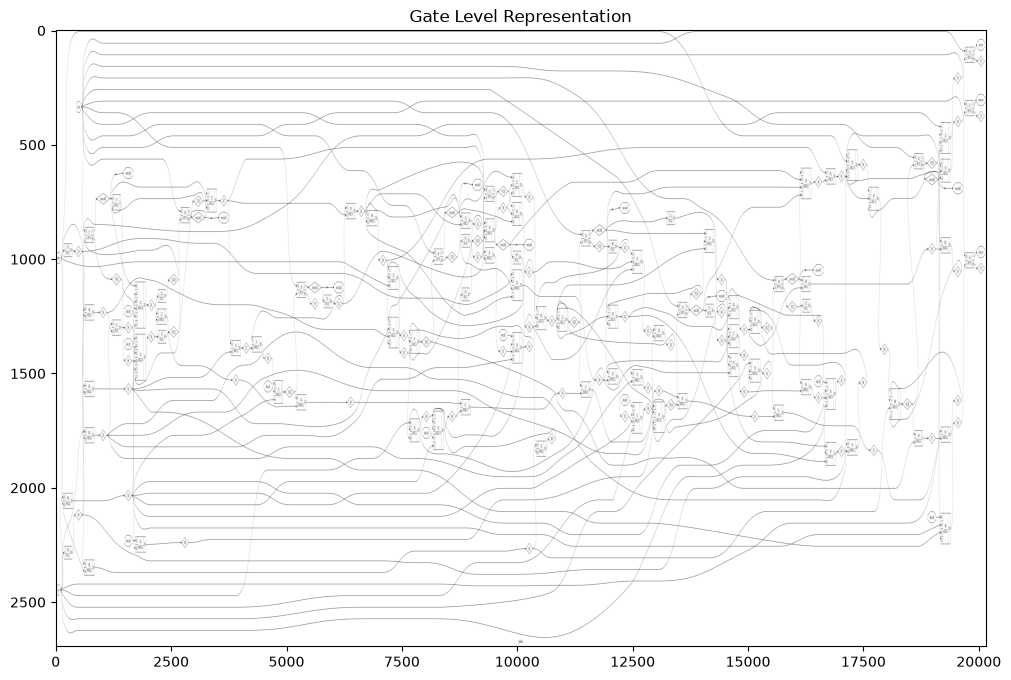

In [2]:
import matplotlib.pyplot as plt


# Update the path to your local folder if necessary
filename=("/home/abde/Downloads/data/graph.png")
#Image(filename="data/graph.png")

# 1. Load the image 
img = plt.imread(filename, format='png')

plt.figure(figsize=(12, 8)) 

# 2. Plot the image
plt.imshow(img, aspect='auto')
plt.title('Gate Level Representation' )

# 3. Display the window
plt.show()



<br>   <br>

#### 2.2.4 Statistics about the design

Using YOSYS stat command provides the following statistics.

Printing statistics.

=== up3down5 ===

        +----------Local Count, excluding submodules.
        | 
      123 wires
      123 wire bits
      123 public wires
      123 public wire bits
       24 ports
       24 port bits
       90 cells
        2   AND3_X1
        2   AOI211_X1
        3   AOI21_X1
        1   AOI221_X1
        2   AOI222_X1
        5   AOI22_X1
       12   DFF_X1
       12   INV_X1
        1   MUX2_X1
        6   NAND2_X1
        3   NAND3_X1
        2   NAND4_X1
        9   NOR2_X1
        3   NOR3_X1
        2   OAI211_X1
        8   OAI21_X1
        2   OR2_X1
        1   OR3_X1
       12   XNOR2_X1
        2   XOR2_X1


#### 2.2.5 Processing the gate level netlist to extract the NETS-GATE MAPPING 
As stated in the section 1, The placement algorithm requires the NETS-GATES mappings as input, whereas the gate level netlist is formated 
as GATES-NETS mapping. In other words, the building blocs of gate level netlist is design gates and all nets connected to its ports. 
    
The following steps are:
  - Parsing the gate level netlist and Extracting the GATES-NETS Mapping.
  - For each net, extract the list of gates which has a port connected to this net. Hence, building the NETS-GATES Mapping.
  - Data cleaning and conversion of  all entries to numerical values.
    

#### 2.2.5.1 Parsing the gate level net list and Extracting the NETS-GATES Mapping

In [3]:
# Parsing the gate level netlist 
!pip install pandas
import re, collections
import pandas as pd

df1_columns=['str_net', 'str_listGates']
df2_columns=['str_gate', 'str_gateTYPE']

# Working dataframes
dataset=pd.DataFrame(columns=df1_columns)
gatesInfo=pd.DataFrame(columns=df2_columns)

new_row=[]

nets = collections.defaultdict(list)

# Read the gate level netlist and Match gates and their Ports 

# Update the path to the gate level netlist if necessary
gate_matches = re.findall(r'(\S+)\s+(\S+)+\s*\((.*?)\);', open("/home/abde/yosys/build/gate_level_netlist5.v").read(), re.DOTALL)
#gate_matches = re.findall(r'(\S+)\s+(\S+)+\s*\((.*?)\);', open("data/gate_level_netlist.v").read(), re.DOTALL)


#print(cell_matches)

for gate_type, gate_id,  ports in gate_matches:
    #print(cell_id)
    if gate_type.startswith('module'): continue
    # Extract net names inside .port(net)
    for net in re.findall(r'\.\w+\(([^)]+)\)', ports):
        nets[net.strip()].append(gate_id.strip())
        #nets[net.strip()].append(cell_id.strip())
        new_row=pd.DataFrame([{'str_gate':gate_id,'str_gateTYPE':gate_type}])
        gatesInfo=pd.concat([gatesInfo,new_row],ignore_index=True)
        
for net, gates in nets.items():
    #print(f'{net:<20} ' + ' '.join(gates))
    new_row=pd.DataFrame([{'str_net':net,'str_listGates':gates}])
    dataset=pd.concat([dataset,new_row],ignore_index=True)
    new_row=pd.DataFrame([{'str_gate':gate_id,'str_gateTYPE':gate_type}])
    gatesInfo=pd.concat([gatesInfo,new_row],ignore_index=True)
    


In [4]:
# Rename all nets and gates with numrical and save all in dataframe
#dataset.head(15)
gatesInfo.head(20)
#dataset.info()
dataset.head()

,str_net,str_listGates
0,up,"[_076_, _085_, _089_, _105_, _111_, _128_, _13..."
1,_018_,"[_076_, _086_, _093_, _094_, _095_]"
2,down,"[_077_, _086_, _089_, _094_, _095_, _127_]"
3,_019_,"[_077_, _085_, _093_, _102_, _151_]"
4,_022_,"[_078_, _079_, _110_, _114_]"


<br>   <br>
####  2.2.5.2 Convert the feature str_net and str_listGates from string into numerical features

In [5]:
dataset['num_net']=pd.factorize(dataset['str_net'])[0]


In [6]:
dataset.head()

,str_net,str_listGates,num_net
0,up,"[_076_, _085_, _089_, _105_, _111_, _128_, _13...",0
1,_018_,"[_076_, _086_, _093_, _094_, _095_]",1
2,down,"[_077_, _086_, _089_, _094_, _095_, _127_]",2
3,_019_,"[_077_, _085_, _093_, _102_, _151_]",3
4,_022_,"[_078_, _079_, _110_, _114_]",4


#### 2.2.5.2 Convert of all entries in dataframe into numerical values 

In [7]:
# Strip catacter _ from gate ID, eg: _80_ becomes 80
def remove_(list_ids):
    return [id.strip("_") for id in list_ids]
dataset['num_listGates']=dataset['str_listGates'].apply(remove_) 


In [8]:
dataset.info()
dataset.head(50)

<class 'pandas.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   str_net        114 non-null    object
 1   str_listGates  114 non-null    object
 2   num_net        114 non-null    int64 
 3   num_listGates  114 non-null    object
dtypes: int64(1), object(3)
memory usage: 3.7+ KB


,str_net,str_listGates,num_net,num_listGates
0,up,"[_076_, _085_, _089_, _105_, _111_, _128_, _13...",0,"[076, 085, 089, 105, 111, 128, 138, 150]"
1,_018_,"[_076_, _086_, _093_, _094_, _095_]",1,"[076, 086, 093, 094, 095]"
2,down,"[_077_, _086_, _089_, _094_, _095_, _127_]",2,"[077, 086, 089, 094, 095, 127]"
3,_019_,"[_077_, _085_, _093_, _102_, _151_]",3,"[077, 085, 093, 102, 151]"
4,_022_,"[_078_, _079_, _110_, _114_]",4,"[078, 079, 110, 114]"
5,_027_,"[_078_, _079_, _113_, _153_]",5,"[078, 079, 113, 153]"
6,_028_,"[_078_, _090_, _102_, _142_, _145_]",6,"[078, 090, 102, 142, 145]"
7,_025_,"[_079_, _143_, _145_]",7,"[079, 143, 145]"
8,_029_,"[_079_, _080_, _125_]",8,"[079, 080, 125]"
9,\_075_[4],"[_080_, _125_, _161_]",9,"[080, 125, 161]"


<br>  <br>

#### 2.2.5.3 Prepare the dataset for the next step


In section 3. design_df is the working dataset with the NETS-GATES Mapping information.
    <br>  <br>

In [9]:
design_df=dataset[['num_net','num_listGates']]
design_df.info()
design_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   num_net        114 non-null    int64 
 1   num_listGates  114 non-null    object
dtypes: int64(1), object(1)
memory usage: 1.9+ KB


,num_net,num_listGates
0,0,"[076, 085, 089, 105, 111, 128, 138, 150]"
1,1,"[076, 086, 093, 094, 095]"
2,2,"[077, 086, 089, 094, 095, 127]"
3,3,"[077, 085, 093, 102, 151]"
4,4,"[078, 079, 110, 114]"


# Section 3.  Using Neural Networks to solve the optimiztion problem

2. Using Neural Netwoks for nonlinear optmization problem

So far the dataframe design_df contains the list of all nets and list of gates connected a each net. 
    Next, we will use these information to optimize the gates placement.

to be completed